## Figures for 'Graded Motor-Preparatory Dynamics Preserve Perceptual Decisions over Short Delays'

In [ ]:
# Importation -----------------
import os
import mne
import warnings
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import matplotlib.ticker as ticker
import numpy as np
import scipy.stats as st
import arviz as az
az.style.use('arviz-white')
warnings.filterwarnings('ignore', category=DeprecationWarning)
warnings.filterwarnings('ignore', category=RuntimeWarning)
warnings.filterwarnings("ignore", message="The figure layout has changed to tight")

def format_ticks(value, _):
    return f" {value:.2f}"

def index_nearest(array,value): #returns the index of the nearest value
    idx = (np.abs(array-value)).argmin()
    return idx

current = os.path.join(os.getcwd()) 
path_behav = os.path.join(current, "analysis", "behavioral_emg")
path_PMA = os.path.join(current, "analysis", "partial_muscle_activation")
path_MBL = os.path.join(current, "analysis", "MBL (8-30Hz)")
path_LRP = os.path.join(current, "analysis", "LRP (C3-C4)")
path_eeg = os.path.join(current, "processing_EEG", "data_saved")

### Plot accuracy, RT, PMET, and MET

Briefly, RT (response time) was fractionated based on the onset of muscle activation leading up to the response, yielding two latencies: the pre-motor execution time (PMET) and the motor execution time (MET).

In [2]:
# Load data to plot -----------
accuracy = pd.read_csv(os.path.join(path_behav, 'accuracy.csv')).to_numpy()
mean_RT = pd.read_csv(os.path.join(path_behav, 'mean_RT.csv')).to_numpy()
mean_PMET = pd.read_csv(os.path.join(path_behav, 'mean_PMET.csv')).to_numpy()
mean_MET = pd.read_csv(os.path.join(path_behav, 'mean_MET.csv')).to_numpy()

# Compute grand average -------------
GA_mean_RT = np.mean(mean_RT, axis = 0)
GA_mean_PMT = np.mean(mean_PMET, axis = 0)
GA_mean_MT = np.mean(mean_MET, axis = 0) 
GA_accuracy = np.mean(accuracy, axis = 0)   

Now we plot behavioral data (accuracy, RT, PMET, and MET) as a function of condition. Stimulus duration of 2 s is shown in red and 0.3 s in blue. Coherence levels (0, 12, and 50%) are displayed on the x-axis.

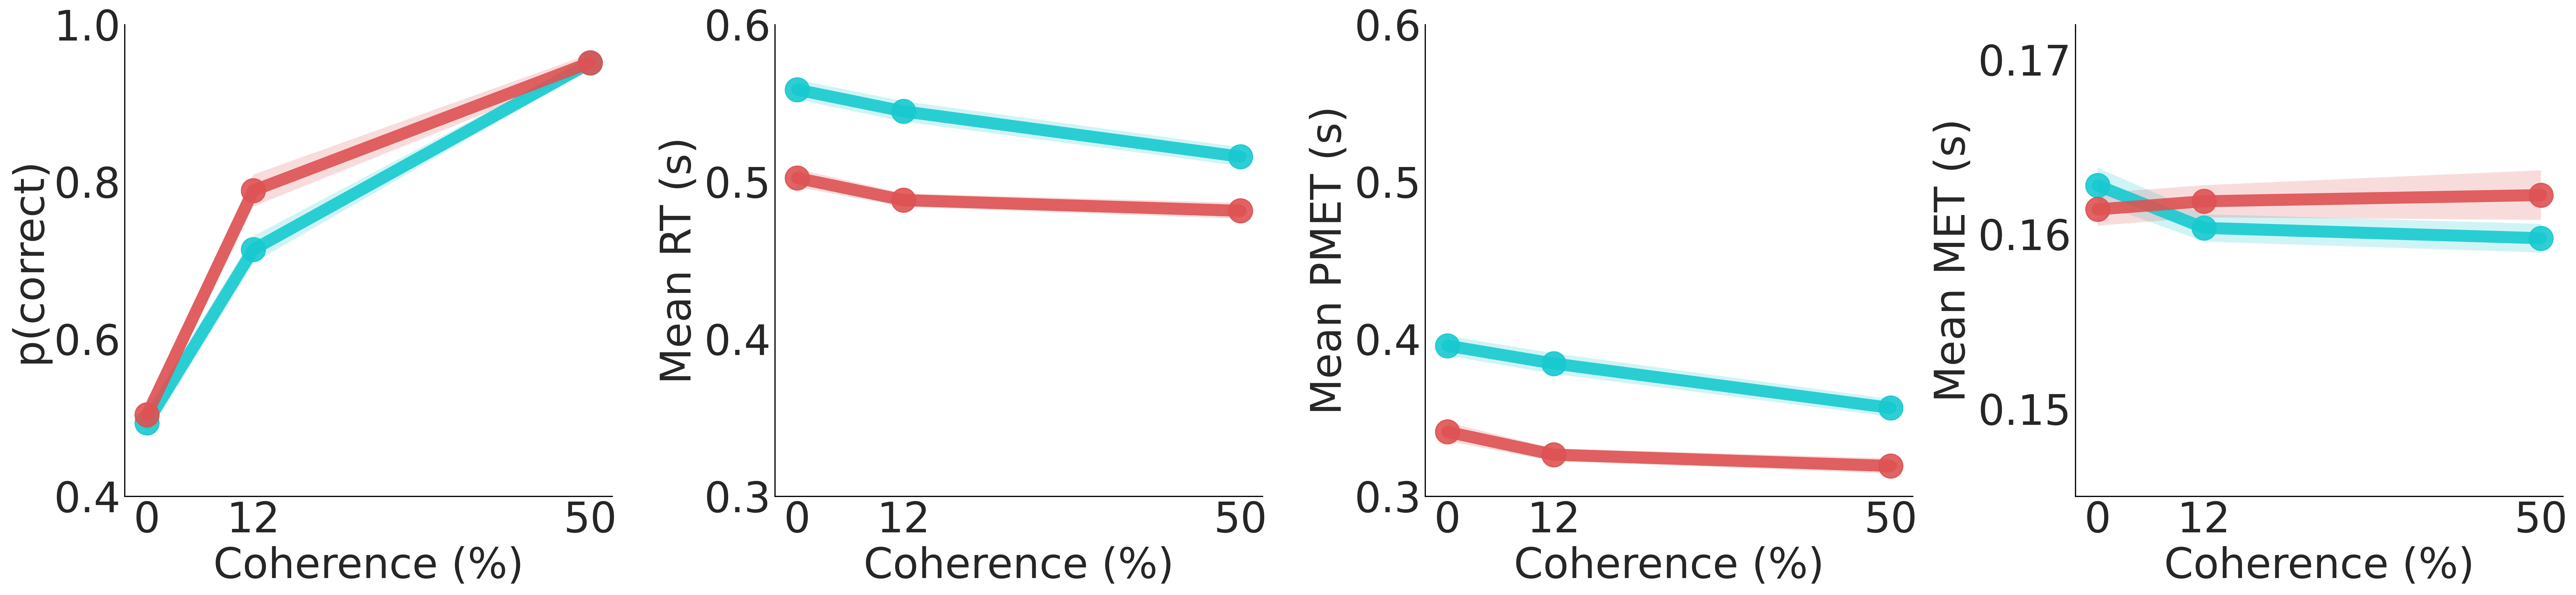

In [3]:
# Plot parameter ------------------------------------------------------
font = 35
alp = 0.2
alp_line = 0.9
nb_subject = 22
possible_coh_levels = np.array([0, 0.12, 0.50])
x_axis = [0, 0.12, 0.50]
x_axis2 = ['0', '12', '50']
linewidth = 10
ms = 20
colors = ['#17cad0', '#DE5253']
labels = ['300 ms', '2000 ms']
condition = [0, 1]
marker = ['o', 'o', 'o', 'o']

y_axis = [
    [0.4, 0.6, 0.8, 1.],      # ACC
    [0.3, 0.4, 0.5, 0.6],     # RT
    [0.3, 0.4, 0.5, 0.6],     # PMET
    [0.15, 0.16, 0.17]        # MET
]

ylim = [
    [0.4, 1.],
    [0.3, 0.6],
    [0.3, 0.6],
    [0.145, 0.172]
]

ylabel = ["p(correct)", "Mean RT (s)", "Mean PMET (s)", "Mean MET (s)"]
data_mean = [GA_accuracy,  GA_mean_RT, GA_mean_PMT, GA_mean_MT]
data_raw = [ accuracy, mean_RT, mean_PMET, mean_MET]

# SE function with Morey correction 
def WS_SE(data, nb_subject):
    dummy = data.reshape((nb_subject, 6))
    mean_per_subject = np.mean(dummy, axis=1)
    grand_mean = np.mean(dummy)

    output = np.zeros((nb_subject, 6))
    for i in range(nb_subject):
        for j in range(6):
            output[i, j] = dummy[i, j] - mean_per_subject[i] + grand_mean

    Morey_factor = np.sqrt(6 / 5)
    output = st.sem(output, axis=0) * Morey_factor
    return output.reshape((2, 3))


# Plot ---------------------------------------------------------------------
fig = plt.figure(figsize=(30, 7), dpi=300)

for k in range(4):
    plt.subplot(1, 4, k + 1)
    SE = WS_SE(data_raw[k], nb_subject)
    x = data_mean[k]

    for i in condition:
        y = x[i*3:(i+1)*3]

        plt.plot(
            possible_coh_levels,
            y,
            color=colors[i],
            alpha=alp_line,
            linewidth=linewidth,
            marker=marker[i],
            label=labels[i],
            ms=ms
        )

        plt.fill_between(
            possible_coh_levels,
            y - SE[i],
            y + SE[i],
            facecolor=colors[i],
            alpha=alp
        )

    plt.ylabel(ylabel[k], fontsize=font)
    plt.xlabel("Coherence (%)", fontsize=font)

    plt.xticks(x_axis, x_axis2, fontsize=font)
    plt.yticks(y_axis[k], y_axis[k], fontsize=font)
    plt.ylim(ylim[k])

    plt.gca().spines[['right', 'top']].set_visible(False)

plt.tight_layout()
plt.show()

### Plot PMA

Briefly, partial muscle activations (PMAs) are subthreshold EMG bursts that do not produce an overt response (e.g., Achard et al., 2025; Dendauw et al., 2024; Servant et al., 2021). According to the extended evidence accumulation theory, PMAs occur when noisy motor preparatory activity transiently exceeds gating inhibition. To estimate their time-varying occurrence rate, PMAs were averaged within 0.1 s time bins separately for each subject, EMG channel, and experimental condition.

In [4]:
# Load data ----------
av_data_bin_stim = np.load(os.path.join(path_PMA, 'av_data_bin_stim.npy'))  #  22s, 2 stim, 3 coh, 2 channel emg (0 opp, 1 same), x bins
av_data_bin_delay = np.load(os.path.join(path_PMA,'av_data_bin_delay.npy')) 
av_data_bin_resp = np.load(os.path.join(path_PMA,'av_data_bin_resp.npy'))
av_data_bin_resp_lock = np.load(os.path.join(path_PMA,'av_data_bin_resp_lock.npy'))

# Select same EMG channel as response
ch = 1
data_stim = av_data_bin_stim[:,:,:, ch, :]
data_delay = av_data_bin_delay[:,:,:, ch, :]
data_resp = av_data_bin_resp[:,:,:, ch, :]
data_resp_lock = av_data_bin_resp_lock[:,:,:, ch, 1:]
data_PMA_same = [data_stim, data_delay, data_resp, data_resp_lock]

# Select opposite EMG channel as response
ch = 0
data_stim_opp = av_data_bin_stim[:,:,:, ch, :]
data_delay_opp = av_data_bin_delay[:,:,:, ch, :]
data_resp_opp = av_data_bin_resp[:,:,:, ch, :]
data_resp_lock_opp = av_data_bin_resp_lock[:,:,:, ch, 1:]
data_opp = [data_stim_opp, data_delay_opp, data_resp_opp, data_resp_lock_opp]


# Time steps -----------------------
tson = np.arange(0.05, 2.05, 0.1)
tsoff = np.arange(0.05, 3.05, 0.1)
trs = np.arange(0.05, 0.35, 0.1)
tresp = np.arange(-0.15, 0, 0.1)
time_steps_PMA = [tson, tsoff, trs, tresp]

In [5]:
# Plot function ---
def WS_SE(data, nb_subject, indice = 6, average = 'all'):
    dummy = data.reshape((nb_subject, indice)) 
    mean_per_subject = np.mean(dummy, axis = 1)
    grand_mean = np.mean(dummy)
    output = np.zeros((nb_subject,indice)) #will contain normalized data
    for i in range(nb_subject):
        for j in range(indice):
            output[i,j] = dummy[i,j] - mean_per_subject[i] +grand_mean
    Morey_factor = np.sqrt(indice/int(indice-1))
    output = st.sem(output, axis = 0)*Morey_factor
     
    if (average == 'all'): output_reshaped = output.reshape((2,3)) 
    else: output_reshaped = output.reshape((indice))
    
    return output_reshaped

def plot_period(data, 
                fsize = [25.5, 7], 
                yname = 'choose variable', 
                select_stim_coh = [[0,1], [0,1,2]],
                compute_SEM = False, 
                xlims = [[-.05, 2.05], [-.025, 3.05], [-0.05, 0.35], [-0.25, 0.01]], 
                ylim = [-2.5,7],
                linewidth = [4,4,4], 
                legend = False, 
                show_xticks=True, 
                colors_all = [['#6AE0FC', '#04A6CC', '#3864B2'] ,['#FF9999', '#FF2929', '#C00000']], 
                time_steps = None,
                w_pad = 0.05,
                mk = '',  
                ylim_full= True,
                width_ratios = [2/3.075, 1, 0.41/3, 0.45/4],
                font = 27,
                variable = None, # PMA, LRP or MBL
                LRP_not_bin = False,
                opp = False): 
    
    """ 
    Return plot of EEG signal selected
        data = [stim, soff, rs, resp] with stim shape (subjects, stim, coherence, time step)
            data[0] : (22 sub, 2 stim, 3 coh, 9831) shape
        average = 'all' or 'stimulus' or coherence
        xlims = [[-.1, 2.1], [-.15, 3.1], [-0.5, 0.5], [-0.5, 0.2]]
        
    """
    l_style = ['-','-']
    x_titles_display = False
    nb_subject = data[0].shape[0]

    
    if compute_SEM:
        SE_margin_stim = np.zeros((2,3,len(time_steps[0])))
        for t in range(len(time_steps[0])):
            SE_margin_stim[:,:,t] = WS_SE(data[0][:,:,:,t], nb_subject)
            
        SE_margin_stimOff = np.zeros((2,3,len(time_steps[1])))
        for t in range(len(time_steps[1])):
            SE_margin_stimOff[:,:,t] = WS_SE(data[1][:,:,:,t], nb_subject)
            
        SE_margin_RS = np.zeros((2,3,len(time_steps[2])))
        for t in range(len(time_steps[2])):
            SE_margin_RS[:,:,t] = WS_SE(data[2][:,:,:,t], nb_subject)
            
        SE_margin_resp = np.zeros((2, 3,len(time_steps[3])))
        for t in range(len(time_steps[3])):
            SE_margin_resp[:,:,t] = WS_SE(data[3][:,:,:,t], nb_subject)
            
        SE_margin = [SE_margin_stim, SE_margin_stimOff, SE_margin_RS, SE_margin_resp]
            
 
    # Plot parameters -----------------------------------
    x_titles = ["Stimulus Onset time-locked (s)", "Stimulus Offset time-locked (s)", "RS time-locked (s)", "Response time-locked (s)"] 
    range_stim = select_stim_coh[0]
    range_coh = select_stim_coh[1]
    
    fig, axs = plt.subplots(1, 4, figsize=fsize, sharey=True, gridspec_kw={'width_ratios': width_ratios}, dpi = 300)
    fig.patch.set_facecolor('white')
    fig.patch.set_alpha(0)

    for i, period in enumerate(data):
        
        if variable in ['LRP', 'MBL']:
            if   (i == 0): 
                start = index_nearest(time_steps[i], 0)
                end = index_nearest(time_steps[i], 1.95)
            elif (i == 1): 
                start = index_nearest(time_steps[i], 0)
                end = index_nearest(time_steps[i], 2.95)
            elif (i == 2): 
                start = index_nearest(time_steps[i], 0)
                end = index_nearest(time_steps[i], 0.3)
                if LRP_not_bin: end = index_nearest(time_steps[i], 0.2)
            elif (i == 3): 
                start = index_nearest(time_steps[i], -0.2)
                end = index_nearest(time_steps[i], 0)
                if LRP_not_bin: start = index_nearest(time_steps[i], -0.25)
                        
        colors = colors_all
        lab = [['0% 300ms','12% 300ms','50% 300ms'], ['0% 2 s','12% 2 s','50% 2 s']]
        GA_plot = period.mean(axis = (0)) # average subjects

        for lag in range_stim:
            for coh in range_coh:
                
                # Variable to plot
                if variable =='LRP':
                    axs[i].plot(time_steps[i][start:end]+ 0.05, GA_plot[lag, coh, start:end], color = colors[lag][coh], label = lab[lag][coh], ls=l_style[lag], linewidth = linewidth[coh], marker = mk)
                    if compute_SEM: axs[i].fill_between(time_steps[i][start:end]+ 0.05, (GA_plot[lag, coh, start:end] ) - SE_margin[i][lag, coh, start:end], (GA_plot[lag, coh, start:end] ) + SE_margin[i][lag, coh, start:end], color=colors[lag][coh], alpha=0.05)
                elif variable == 'PMA':
                    axs[i].plot(time_steps[i], GA_plot[lag, coh], color = colors[lag][coh], label = lab[lag][coh], ls=l_style[lag], linewidth = linewidth[coh], marker = mk)
                    if compute_SEM: axs[i].fill_between(time_steps[i], (GA_plot[lag, coh] ) - SE_margin[i][lag, coh], (GA_plot[lag, coh] ) + SE_margin[i][lag, coh], color=colors[lag][coh], alpha=0.05)
                elif variable == 'MBL':
                    axs[i].plot(time_steps[i][start:end]+ 0.05, GA_plot[lag, coh, start:end], color = colors[lag][coh], label = lab[lag][coh], ls=l_style[lag], linewidth = linewidth[coh], marker = mk)
                    if compute_SEM: axs[i].fill_between(time_steps[i][start:end]+ 0.05, (GA_plot[lag, coh, start:end] ) - SE_margin[i][lag, coh, start:end], (GA_plot[lag, coh, start:end] ) + SE_margin[i][lag, coh, start:end], color=colors[lag][coh], alpha=0.05)
                    
                
                
                if x_titles_display: axs[i].set_xlabel(x_titles[i], fontsize=font)
                axs[i].set_xlim(xlims[i])
                axs[i].tick_params(axis='both', labelsize=font)
                axs[i].set_ylim(ylim)
                axs[i].axvline(0, c='k')
                axs[i].axhline(0, c='k')
                axs[i].patch.set_facecolor('white')
                if i !=0: axs[i].yaxis.set_tick_params(size=0)
                if legend and i==0 : axs[i].legend(ncol = 2, loc='upper center', title='Stimulus duration and coherence', 
                                                   frameon=True, fontsize=font-10, title_fontsize='xx-large')
                        
        # delete countour lines
        for spine in ['top', 'right', 'left']: axs[i].spines[spine].set_visible(False)
        if (variable == 'PMA'): axs[i].spines['bottom'].set_visible(False)
        
    axs[0].set_ylabel(yname, fontsize=font)
    axs[0].yaxis.set_major_formatter(FuncFormatter(format_ticks))
    
    # y-axis
    if variable == 'PMA':
        if ylim_full: axs[0].set_yticks([0, 0.05, 0.10, 0.15], ['0', '0.05', '0.10','0.15'], fontsize=font)
        if not ylim_full: 
            if opp:axs[0].set_yticks([0, 0.025], ['0', '0.025'], fontsize=font)
            else:axs[0].set_yticks([0, 0.025,0.05], ['0', '0.025', '0.05'], fontsize=font)
    elif variable == 'LRP':
        if ylim_full: axs[0].set_yticks([-2,-1,0], ['  -2 ', '  -1 ', '  0 '], fontsize=font)
        if not ylim_full: axs[0].set_yticks([-1,0], ['-1 ', '0 '], fontsize=font)


    
    if show_xticks:
        x_stim_value = [0, 0.3, 1, 2]
        axs[0].set_xticks(x_stim_value, [0, '0.3', 1, 2])
        x_delay_value = [0, 1 ,2 , 3]
        axs[1].set_xticks(x_delay_value)
        axs[2].set_xticks( [0, 0.3], ['0', 0.3])
        axs[3].set_xticks([-0.2, 0], [-0.2, '0'])
        
        axs[0].yaxis.set_tick_params(size=10, direction='in')
        axs[0].xaxis.set_tick_params(size=10, direction='inout')
        axs[1].xaxis.set_tick_params(size=10, direction='inout')
        axs[2].xaxis.set_tick_params(size=10, direction='inout')
        axs[3].xaxis.set_tick_params(size=10, direction='inout')
    
    
    # show line of offset stimulus
    axs[0].axvline(0.3, c="#3EB6D4", ls = '--', lw= 2)
    axs[0].axvline(2.0, c='#FF2929', ls = '--', lw= 2)
    
    plt.tight_layout(w_pad=w_pad)
    
    return fig

Now, we plot PMA rate per 0.1s bin for EMG channel associated with the response:

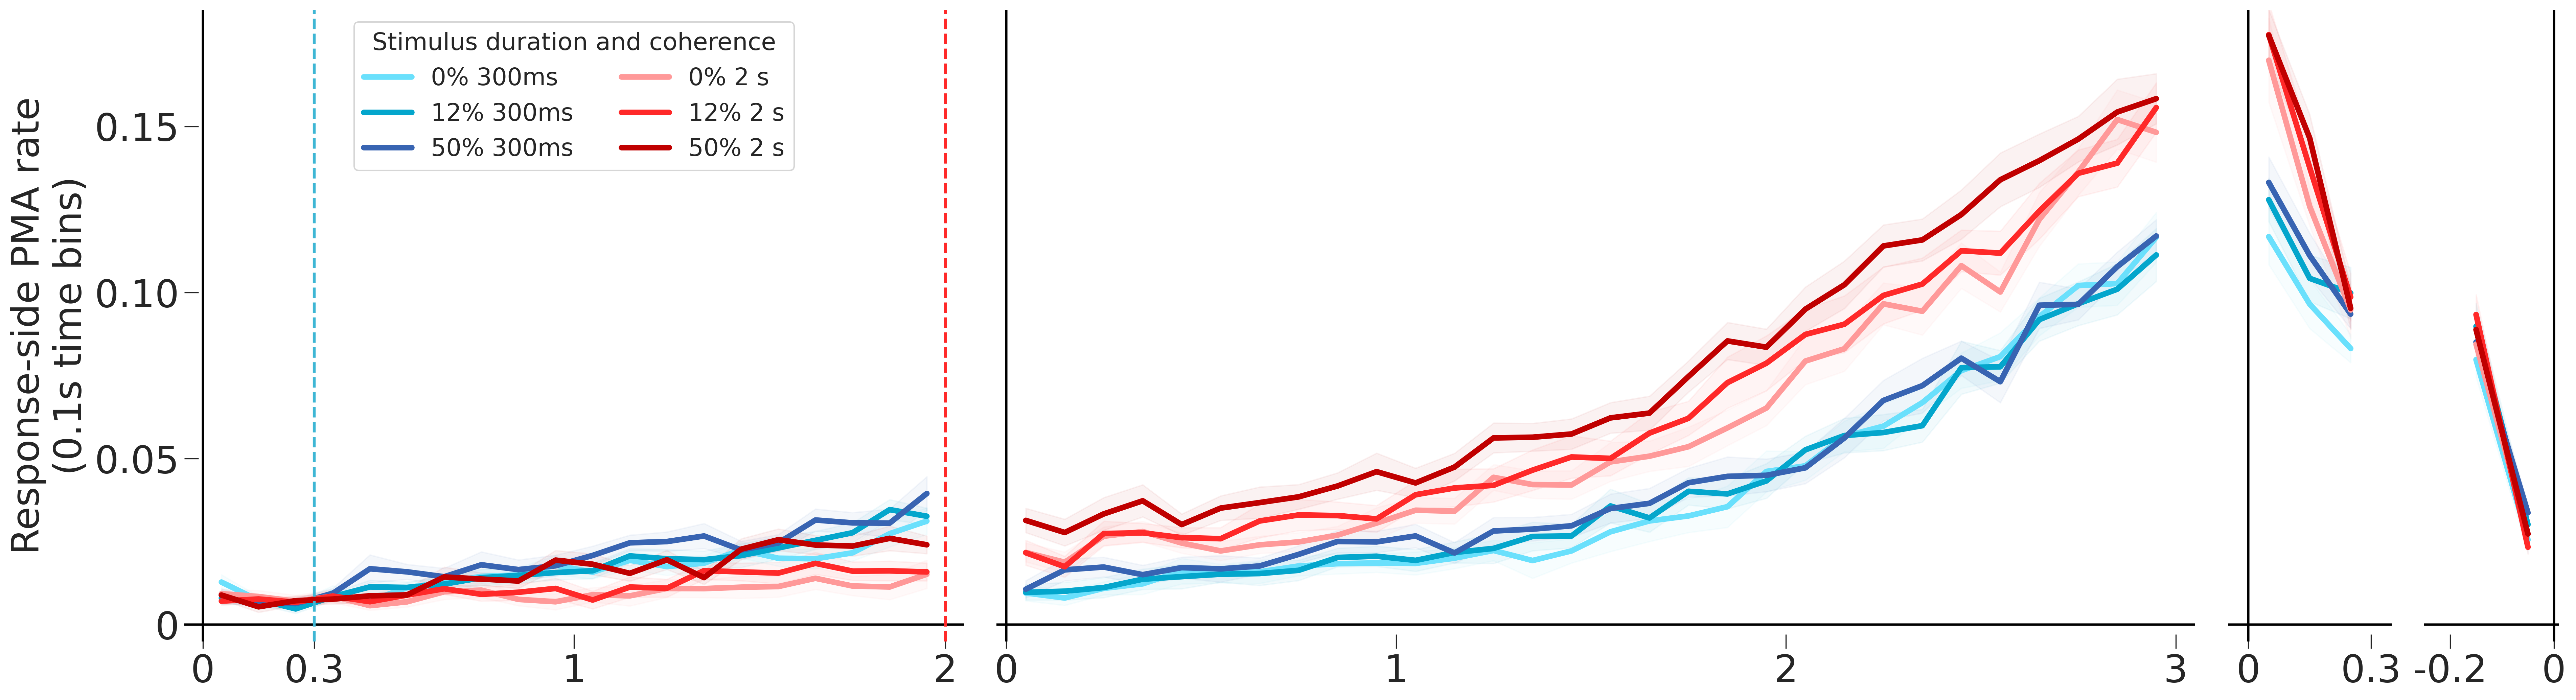

In [6]:
yname = f'Response-side PMA rate\n(0.1s time bins)'
ylim = [-0.005, 0.185]

plot_period(data_PMA_same, variable = 'PMA', ylim = ylim, legend=True, compute_SEM=True, 
            yname = yname, time_steps= time_steps_PMA)
plt.show()

And plot PMA rate in EMG channel not associated with response:

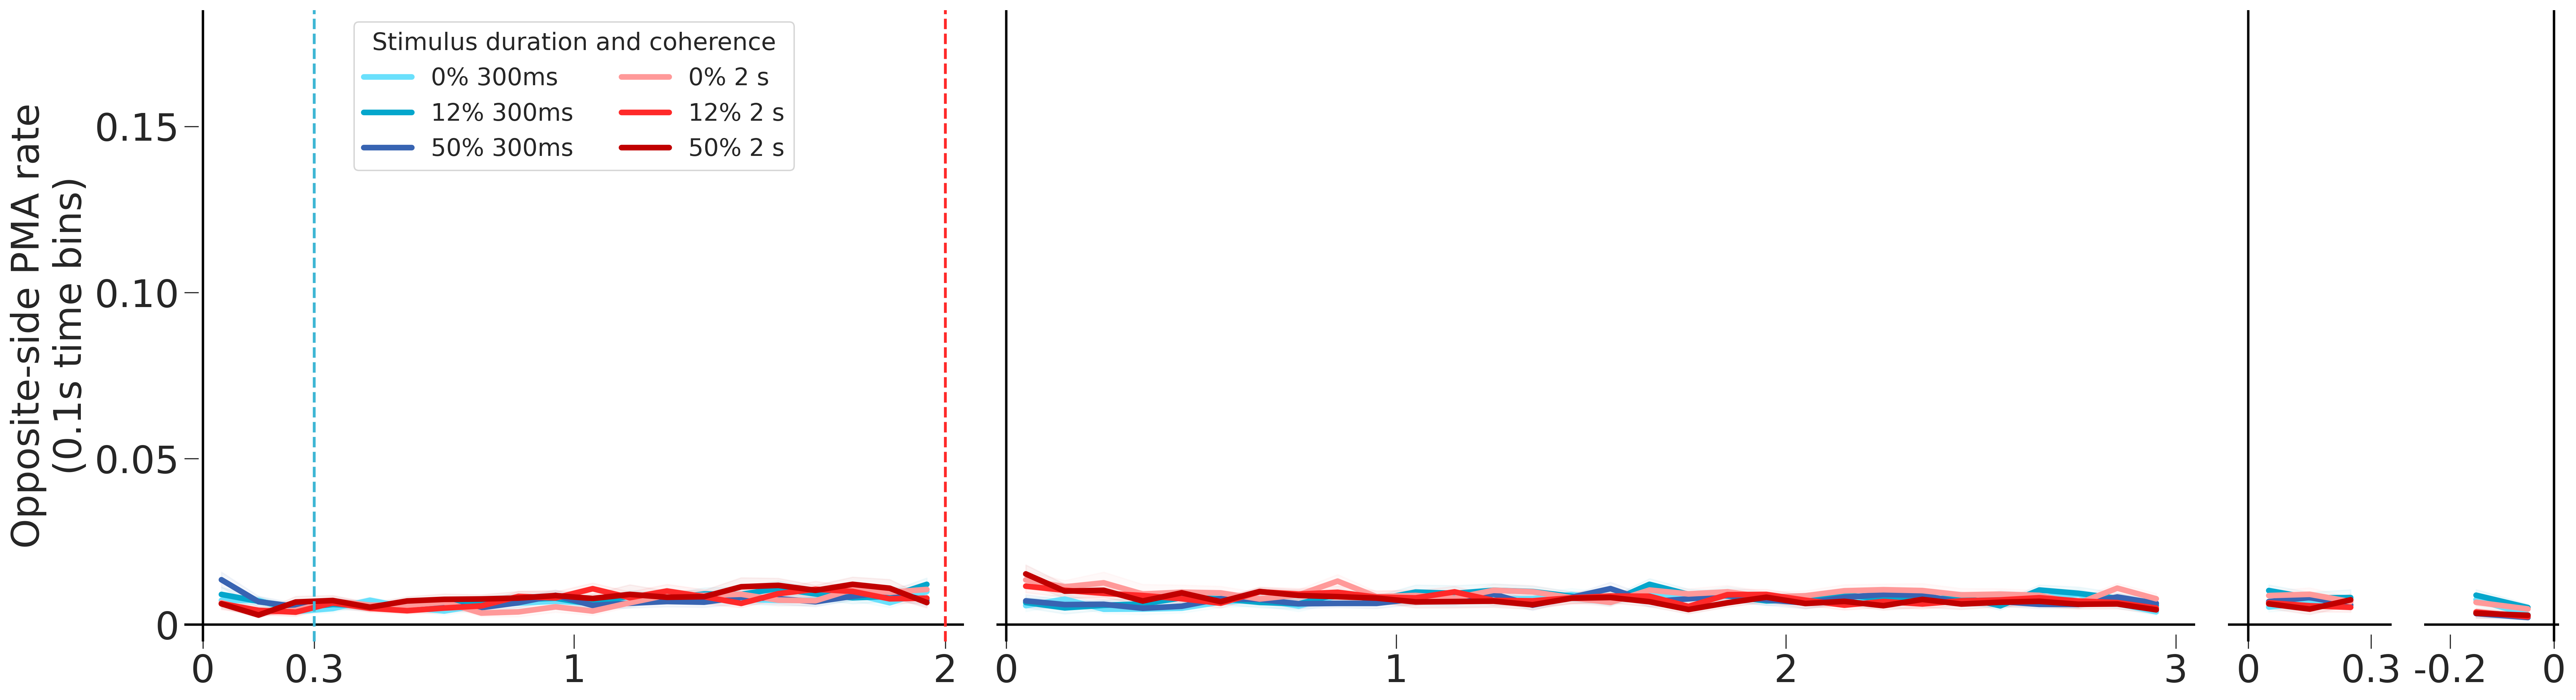

In [7]:
yname = f'Opposite-side PMA rate\n(0.1s time bins)'
plot_period(data_opp, variable = 'PMA', ylim = ylim, legend=True, compute_SEM=True, 
            yname = yname, time_steps= time_steps_PMA)
plt.show()

### Plot LRP

Briefly, LRP is a negative-going potential that precedes unilateral movements and is commonly interpreted as reflecting effector-specific motor activation in contralateral motor-related regions, indexing late-stage response preparation (Gratton et al., 1988; de Jong et al., 1988; Eimer, 1998). 

In [8]:
# Load data -------
reorg_onset_conditions = np.load(os.path.join(path_LRP, f"av_epochs_onset_reorg.npy")) # shape (22 subjects, 2 stim, 3 coh, 64eeg, x times step, 3 press)
reorg_offset_conditions = np.load(os.path.join(path_LRP, f"av_epochs_offset_reorg.npy"))
reorg_rs_conditions = np.load(os.path.join(path_LRP, f"av_epochs_rs_reorg.npy"))
reorg_resp_conditions = np.load(os.path.join(path_LRP, f"av_epochs_resp_reorg.npy"))

no_reorg_onset_conditions = np.load(os.path.join(path_LRP, f"av_epochs_onset_no_reorg.npy"))
no_reorg_offset_conditions = np.load(os.path.join(path_LRP, f"av_epochs_offset_no_reorg.npy"))
no_reorg_rs_conditions = np.load(os.path.join(path_LRP, f"av_epochs_rs_no_reorg.npy"))
no_reorg_resp_conditions = np.load(os.path.join(path_LRP, f"av_epochs_resp_no_reorg.npy"))

# Load time step ------
time_steps_onset = np.load(os.path.join(path_eeg, "time_steps.npy"))
time_steps_offset = np.load(os.path.join(path_eeg,"epoch_times_stimOFF.npy"))
time_steps_rs = np.load(os.path.join(path_eeg,"epoch_times_RS.npy"))
time_steps_resp = np.load(os.path.join(path_eeg,"epoch_times_resp.npy"))
time_steps = [time_steps_onset, time_steps_offset, time_steps_rs, time_steps_resp]

# Parameters and infos ------------------
ch_type = np.full(64,'eeg')
sf = 1024
ch_names = ['Fp1', 'AF7', 'AF3', 'F1', 'F3', 'F5', 'F7', 'FT7', 'FC5', 'FC3', 'FC1', 'C1', 'C3', 'C5', 'T7', 'TP7',
            'CP5', 'CP3', 'CP1', 'P1', 'P3', 'P5', 'P7', 'P9', 'PO7', 'PO3', 'O1', 'Iz', 'Oz', 'POz', 'Pz', 'CPz',
            'Fpz', 'Fp2', 'AF8', 'AF4', 'AFz', 'Fz', 'F2', 'F4', 'F6', 'F8', 'FT8', 'FC6', 'FC4', 'FC2', 'FCz', 'Cz',
            'C2', 'C4', 'C6', 'T8', 'TP8', 'CP6', 'CP4', 'CP2', 'P2', 'P4', 'P6', 'P8', 'P10', 'PO8', 'PO4', 'O2']

ch_type = np.full(64,'eeg')
info = mne.create_info(ch_names = ch_names, sfreq = sf, ch_types = ch_type)
info.set_montage('biosemi64')

<Info | 8 non-empty values
 bads: []
 ch_names: Fp1, AF7, AF3, F1, F3, F5, F7, FT7, FC5, FC3, FC1, C1, C3, C5, ...
 chs: 64 EEG
 custom_ref_applied: False
 dig: 67 items (3 Cardinal, 64 EEG)
 highpass: 0.0 Hz
 lowpass: 512.0 Hz
 meas_date: unspecified
 nchan: 64
 projs: []
 sfreq: 1024.0 Hz
>

First, electrodes of interest were selected based on inspection of the grand-average difference topography for leftward versus rightward motion targets at response execution, classically centered over motor areas (e.g., C3/C4; Twomey et al., 2016).

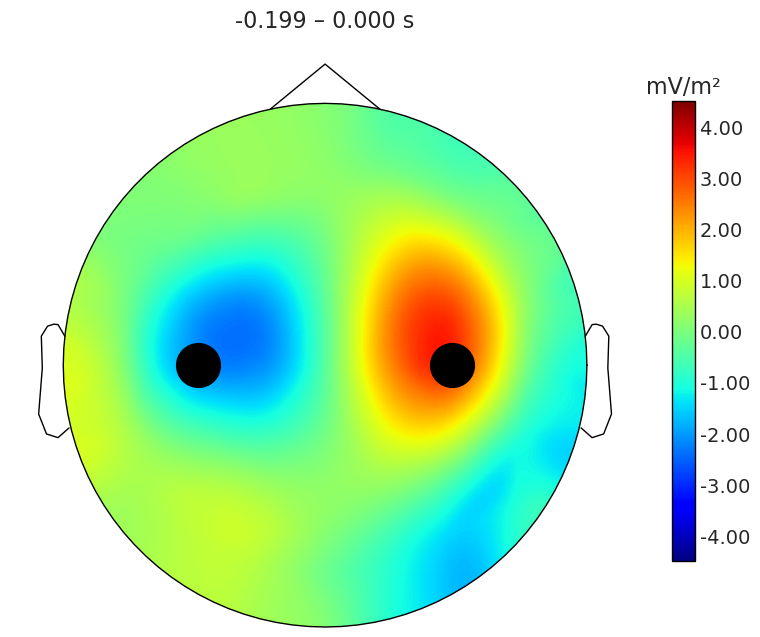

In [9]:
# Plot LRP topography -----------------------------------
epoch_LRP_leftR = no_reorg_resp_conditions[:,:,:,:,:,0] # note that data is in µV/m²  
epoch_LRP_rightR = no_reorg_resp_conditions[:,:,:,:,:,1]  
epoch_interest = epoch_LRP_rightR - epoch_LRP_leftR 

# Reconstruct mne object
GA_LRP = np.mean(epoch_interest, axis = (0,1,2)) # mean subject, lag, coh
GA_MNE = mne.EvokedArray(GA_LRP, info = info, tmin = time_steps_resp[0]) # mne object to use mne toolbox

# EEG channel to display  ---------------
_channels = [np.isin(GA_MNE.ch_names, ch) for ch in [("C3", "C4")]]
mask = np.zeros(GA_MNE.data.shape, dtype=bool) 
for _chs in _channels:
    mask[_chs, :] = True  # mask over eeg dot channel
mask_params = dict(markersize=12, marker='o', markerfacecolor='black')  # dots display settings

# Pre-compute figure
GA_topo = GA_MNE.plot_topomap(times = -0.100,  average = 0.2, show_names=False, 
                              units="mV/m²", scalings=dict(eeg=1e-3), sensors = False,
                              size = 5, show = False, cmap = 'jet', contours= 0, 
                              vlim = (-4.5,4.5),  mask=mask, mask_params=mask_params)

    
# Change topography format -------------
fig = GA_topo.figure
cbar = fig.axes[-1]  # colorbar
cbar.yaxis.set_major_formatter(ticker.FormatStrFormatter('%.02f'))
cbar.locator = ticker.MaxNLocator(nbins=5)
cbar.tick_params(labelsize=14)
fig.canvas.draw()

We computed the LRP at C3/C4 by subtracting, for each trial, the activity at the electrode ipsilateral to the responding hand from that at the contralateral electrode, using current source density (CSD)–transformed signals, and defined a function to visualize the resulting time course.

In [10]:
# Select site of interest (C3/C4) ---------------------------------------------------
C3 = np.where((np.array(ch_names) == 'C3'))[0][0]
C4 = np.where((np.array((ch_names)) == 'C4'))[0][0]
elects_left = [C3] 
elects_right = [C4] 

# Computed the LRP as contralateral minus ipsilateral activity --------------------------
# Note that the data were already reorganized such that the contralateral side corresponds 
# to the right hemisphere (C4) and the ipsilateral side to the left hemisphere (C3).

# Stim onset ---
temp_ = reorg_onset_conditions[:,:,:,:,:,2] *1e-3 # convert µV/m² in mV/m² thanks to *1e-3
data_stim_lrp = (temp_[:,:,:,elects_left,:].mean(axis=3) - temp_[:,:,:,elects_right,:].mean(axis=3))  

# Stim offset ---
temp_ = reorg_offset_conditions[:,:,:,:,:,2]  *1e-3 
data_soff_lrp = (temp_[:,:,:,elects_left,:].mean(axis=3) - temp_[:,:,:,elects_right,:].mean(axis=3))    

# RS ---
temp_ = reorg_rs_conditions[:,:,:,:,:,2]  *1e-3
data_rs_lrp = (temp_[:,:,:,elects_left,:].mean(axis=3) - temp_[:,:,:,elects_right,:].mean(axis=3))   

# Resp ---
temp_ = reorg_resp_conditions[:,:,:,:,:,2]  *1e-3 
data_resp_lrp = (temp_[:,:,:,elects_left,:].mean(axis=3) - temp_[:,:,:,elects_right,:].mean(axis=3))   

data_lrp = [data_stim_lrp, data_soff_lrp, data_rs_lrp, data_resp_lrp]

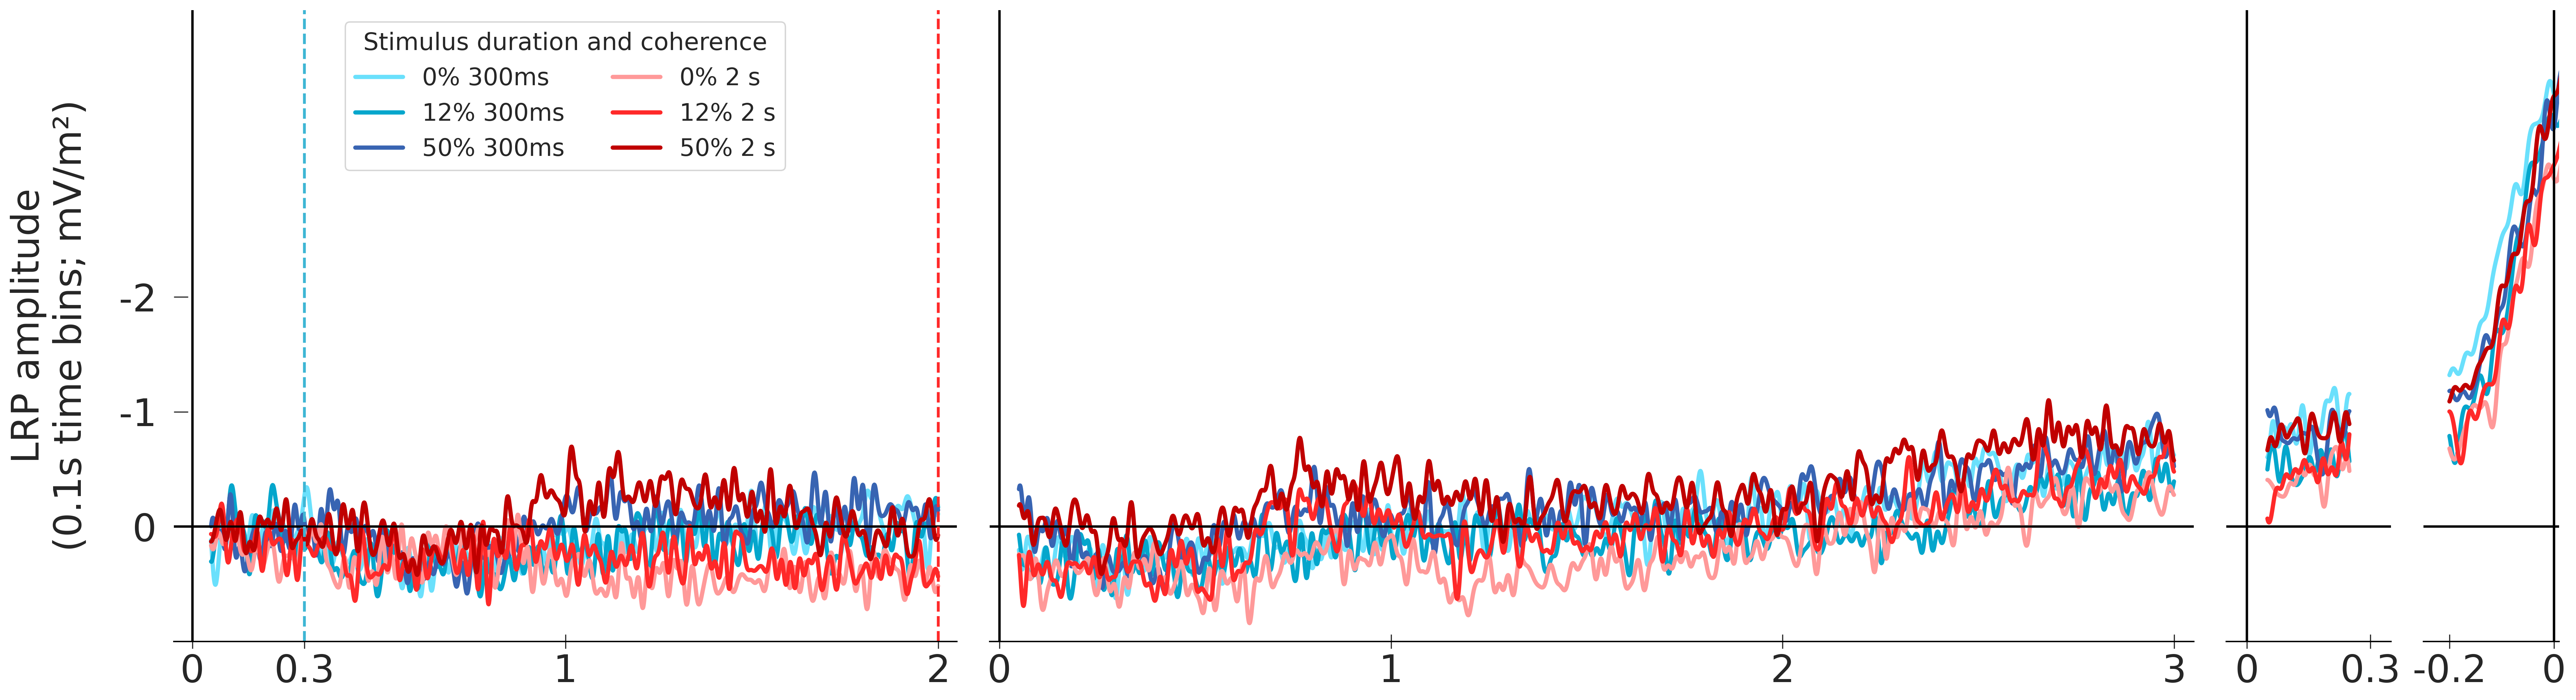

In [11]:
yname = f'LRP amplitude\n(0.1s time bins; mV/m²)'
ylim =  [1, -4.5]
plot_period(data_lrp, variable = 'LRP', ylim = ylim, legend=True, time_steps=time_steps,
            compute_SEM=False, yname = yname,  linewidth = [3,3,3], LRP_not_bin=True)
plt.show()

Next, we averaged the LRP time course within 0.1 s bins to match the temporal resolution used in the previous PMA analyses. Statistical analyses were then performed on these binned LRP values (see Methods and Results sections for details).

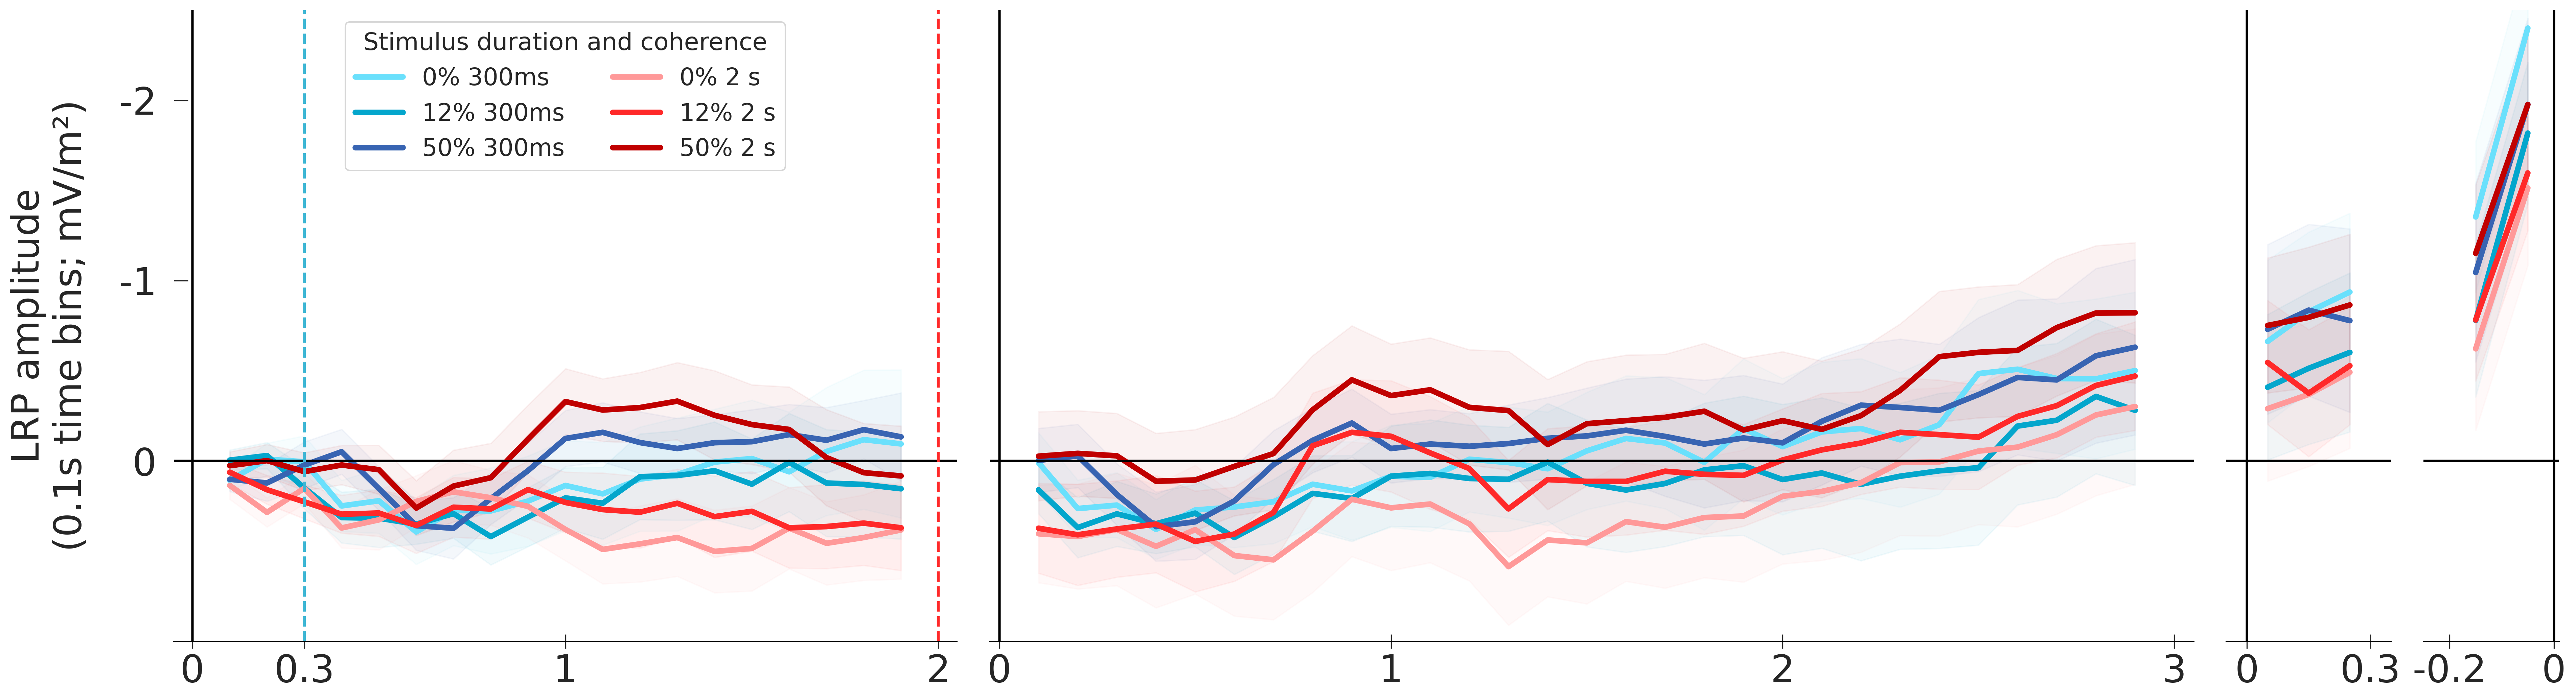

In [12]:
# Load 0.1s data LRP binned -----------------------------

data = np.load(os.path.join(path_LRP,"data_lrp_binned.npz"), allow_pickle=True)
data_lrp_binned = [data["stim"], data["delay"], data["rs"], data["resp"]]

data = np.load(os.path.join(path_LRP,"time_steps_bin.npz"), allow_pickle=True)
time_steps_bin = [data["stim"], data["delay"], data["rs"], data["resp"]]

data = np.load(os.path.join(path_LRP,"bin_period.npz"), allow_pickle=True)
bin_period = [data["bin_stim"], data["bin_delay"], data["bin_rs"], data["bin_resp"]]


# Plot LRP 0.1s time bins ------------------------------
yname = f'LRP amplitude\n(0.1s time bins; mV/m²)'
ylim = [1, -2.5]

plot_period(data_lrp_binned, variable = 'LRP', ylim = ylim, legend=True, 
             time_steps = time_steps_bin, compute_SEM=True, yname = yname)
plt.show()

### Plot MBL (8-30Hz)

Briefly, MBL reflects the relative decrease in mu–beta amplitude (8–30 Hz) over the contralateral hemisphere as motor plans are formed, indexing the lateralized preparatory modulation of motor cortical activity (Pfurtscheller & Lopes da Silva, 1999). 

In [13]:
# Load data -------
reorg_onset_conditions = np.load(os.path.join(path_MBL, f"av_epochs_onset_reorg.npy")) 
reorg_offset_conditions = np.load(os.path.join(path_MBL, f"av_epochs_offset_reorg.npy"))
reorg_rs_conditions = np.load(os.path.join(path_MBL, f"av_epochs_rs_reorg.npy"))
reorg_resp_conditions = np.load(os.path.join(path_MBL, f"av_epochs_resp_reorg.npy"))

no_reorg_onset_conditions = np.load(os.path.join(path_MBL, f"av_epochs_onset_no_reorg.npy"))
no_reorg_offset_conditions = np.load(os.path.join(path_MBL, f"av_epochs_offset_no_reorg.npy"))
no_reorg_rs_conditions = np.load(os.path.join(path_MBL, f"av_epochs_rs_no_reorg.npy"))
no_reorg_resp_conditions = np.load(os.path.join(path_MBL, f"av_epochs_resp_no_reorg.npy"))

# Load time step ------
time_TF_onset = np.load(os.path.join(path_eeg, "time_TF_onset_300ms.npy"))
time_TF_offset = np.load(os.path.join(path_eeg,"time_TF_offset_300ms.npy"))
time_TF_rs = np.load(os.path.join(path_eeg,"time_TF_rs_300ms.npy"))
time_TF_resp = np.load(os.path.join(path_eeg,"time_TF_resp_300ms.npy"))
time_steps_TF = [time_TF_onset, time_TF_offset, time_TF_rs, time_TF_resp]

freq_stft = np.load(os.path.join(path_eeg,"freq_stft_300ms.npy"))
frqs = np.where(freq_stft <= 30)[0]

# Parameters and infos for TFA ------------------
sf = 10 # STFT temporal sampling rate (100 ms step, original sf=1024 Hz)
info = mne.create_info(ch_names = ch_names, sfreq = sf, ch_types = ch_type)
info.set_montage('biosemi64')


# Compute power lateraliszation MBL (contro - ipsi) ---------------------
C3 = np.where((np.array(ch_names) == 'C3'))[0][0]
C4 = np.where((np.array((ch_names)) == 'C4'))[0][0]
elects_left = [C3] 
elects_right = [C4] 
press = 2 # 2 for all trial (right or left press)

# Stim onset
temp_ = (reorg_onset_conditions[:,:,:,:,frqs,:,:].mean(axis=4)) *1e-3 # convert µV/m² in mV/m² thanks to *1e-3
temp_ = temp_[:,:,:,:,:, press]
data_stim = (temp_[:,:,:,elects_left,:].mean(axis=3) - temp_[:,:,:,elects_right,:].mean(axis=3))    # shape (subjects, 2 stims, 3 coh,  time) 

# Stim offset
temp_ = (reorg_offset_conditions[:,:,:,:,frqs,:,:].mean(axis=4))  *1e-3 
temp_ = temp_[:,:,:,:,:,press]
data_soff = (temp_[:,:,:,elects_left,:].mean(axis=3) - temp_[:,:,:,elects_right,:].mean(axis=3))    

# RS
temp_ = (reorg_rs_conditions[:,:,:,:,frqs,:,:].mean(axis=4))  *1e-3
temp_ = temp_[:,:,:,:,:,press]
data_rs = (temp_[:,:,:,elects_left,:].mean(axis=3) - temp_[:,:,:,elects_right,:].mean(axis=3))   

# Resp
temp_ = (reorg_resp_conditions[:,:,:,:,frqs,:,:].mean(axis=4))  *1e-3 
temp_ = temp_[:,:,:,:,:,press]
data_resp = (temp_[:,:,:,elects_left,:].mean(axis=3) - temp_[:,:,:,elects_right,:].mean(axis=3))   

# all period in containers
data_MBL = [data_stim, data_soff, data_rs, data_resp]

We plot topography (right press - left press) for MBL:

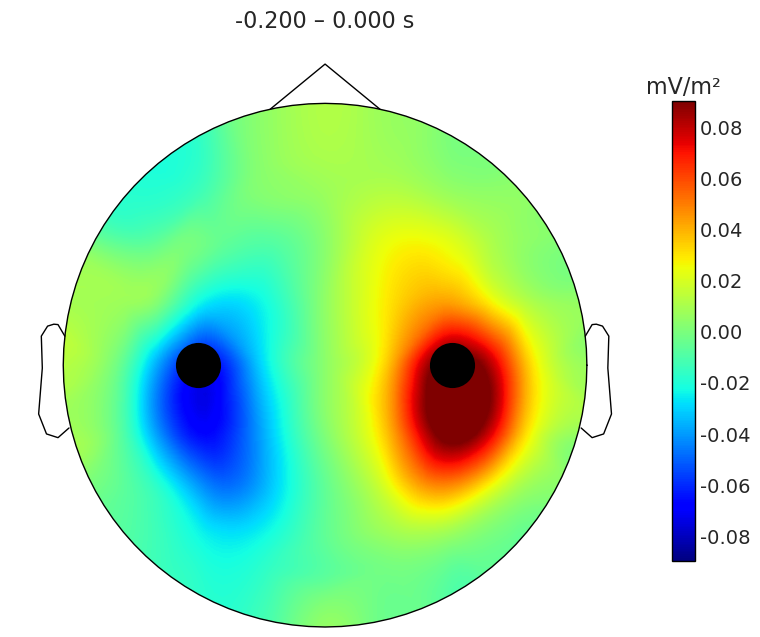

In [14]:
# Select MBL frequency band (8-30Hz) ---------------
epoch_interest = no_reorg_resp_conditions[:,:,:,:,frqs, :,:].mean(axis=4) # average band frequency of interest
epoch_leftR = epoch_interest[:,:,:,:, :,0]
epoch_rightR = epoch_interest[:,:,:,:,:, 1]
epoch_interest = epoch_rightR - epoch_leftR 
GA_epochsTF = epoch_interest.mean(axis = (0,1,2)) # grand average by condition

# Reconstruct mne object
GA_MNE = mne.EvokedArray(GA_epochsTF, info = info, tmin = time_TF_resp[0])

# EEG channel to display  ---------------
_channels = [np.isin(GA_MNE.ch_names, ch) for ch in [("C3", "C4")]]
mask = np.zeros(GA_MNE.data.shape, dtype=bool)
for _chs in _channels:
    mask[_chs, :] = True  
mask_params = dict(markersize=12, marker='o', markerfacecolor='black')

# Pre-compute figure
GA_topo = GA_MNE.plot_topomap(times = -0.1,  average = 0.25, show_names=False, sensors = False, 
                              units="mV/m²", scalings=dict(eeg=1e-3), # to mV/m² because data is in µV/m²
                              size = 5, show = False, cmap = 'jet', contours=0, 
                              mask=mask, mask_params=mask_params, vlim=(-0.09, 0.09) )

# Change topography format -------------
fig = GA_topo.figure
cbar = fig.axes[-1]  # la colorbar est le dernier axe
cbar.yaxis.set_major_formatter(ticker.FormatStrFormatter('%.2f'))
cbar.locator = ticker.MaxNLocator(nbins=5)
cbar.tick_params(labelsize=14)
fig.canvas.draw()


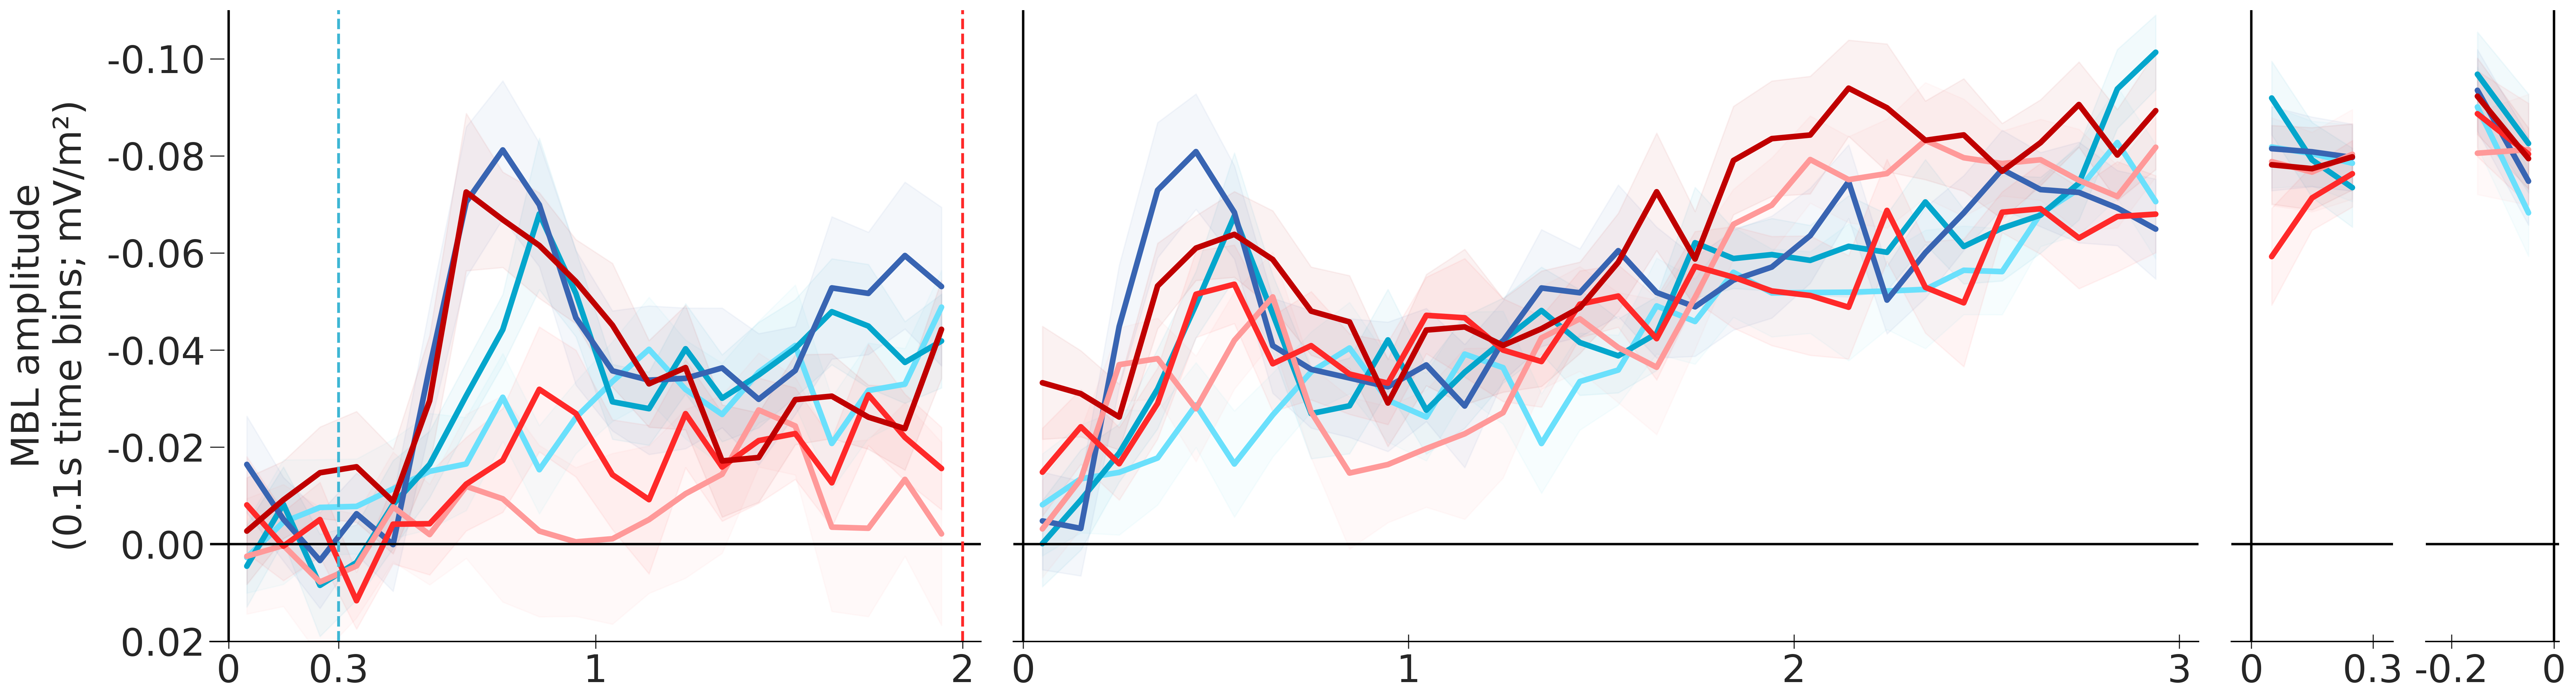

In [15]:
# Plot MBL 0.1s time bins (STFT with 300ms window and 100ms step) ------------------------------
yname = f'MBL amplitude\n(0.1s time bins; mV/m²)'
ylim = [0.02, -0.11]

plot_period(data_MBL, variable = 'MBL', ylim = ylim, legend=False, 
             time_steps = time_steps_TF, compute_SEM=True, yname = yname)
plt.show()